# 08 · Evaluation: Measuring Report Quality, Cost and Speed

"It produced a nice-looking report once" is not evidence. To make decisions (does the critic loop help? is it worth
the extra cost?) we need **repeatable measurements over a benchmark set**.

### What we measure
| Type | Metric | How | Cost |
|---|---|---|---|
| Deterministic | citation validity (invalid/unused markers) | regex vs source map | free |
| Deterministic | grounding rate (claims whose URLs were really retrieved) | fact-check statuses | free |
| Deterministic | # sources, # distinct domains, mean credibility | from the run state | free |
| Deterministic | failed researchers, critic iterations | from the run state | free |
| Operational | wall time, LLM calls, tokens | callback handler + timer | free |
| Judgement | relevance, completeness, specificity (1–5) | **LLM-as-judge** | 1 call/report |

**LLM-as-judge caveats:** judges are noisy and can prefer outputs similar to their own style. We mitigate this by
(1) using a **different model** for judging than for writing, (2) a fixed rubric with anchored scales,
(3) treating small score differences as noise.

### Experiment
Two configurations of the *same* graph, on the same questions:
- **`single_pass`**: critic scores the report but never sends work back (`max_iterations=1`).
- **`critic_loop`**: the critic may trigger one extra research round (`max_iterations=2`).

### Budget awareness
One real run uses ~20–35 LLM requests; the OpenRouter free tier allows 50/day (1,000/day after a one-time
$10 credit purchase, or use a Groq key). So this notebook:
- saves each result as soon as it finishes and **skips completed runs** when re-executed (resume across days);
- has a **`DRY_RUN`** mode with stub agents that exercises the entire evaluation pipeline for free.

In [1]:
from nb_setup import setup, timer
ROOT = setup()

DRY_RUN = True          # True: stub agents (free, tests the pipeline). False: real LLM runs (uses API quota).
N_QUESTIONS = 3         # increase as quota allows (max 5)
CONFIGS = {
    "single_pass": {"max_sub_questions": 3, "max_tool_calls": 3, "max_iterations": 1},
    "critic_loop": {"max_sub_questions": 3, "max_tool_calls": 3, "max_iterations": 2},
}
RESULTS_CSV = ROOT / "data" / ("08_eval_results_dryrun.csv" if DRY_RUN else "08_eval_results.csv")
print(f"DRY_RUN={DRY_RUN} | questions={N_QUESTIONS} | configs={list(CONFIGS)} | results -> {RESULTS_CSV.name}")

API keys:
  GROQ_API_KEY         MISSING
  OPENROUTER_API_KEY   set
  TAVILY_API_KEY       set
  LANGSMITH_API_KEY    set
  LangSmith tracing    true


LLM cache: data\llm_cache.sqlite
DRY_RUN=True | questions=3 | configs=['single_pass', 'critic_loop'] | results -> 08_eval_results_dryrun.csv


## 1 · Benchmark questions

Deliberately diverse research types, because a system tuned on one type of question can fail on others.

In [2]:
EVAL_QUESTIONS = [
    ("technical",   "What are the main techniques for reducing hallucinations in large language models as of 2026?"),
    ("comparative", "Compare LangGraph, CrewAI and AutoGen for building multi-agent LLM systems."),
    ("trend",       "What is the current state of solid-state battery commercialization for electric vehicles?"),
    ("factual",     "How does retrieval-augmented generation work and what are its most common failure modes?"),
    ("exploratory", "What effects has generative AI had on software developer employment and hiring?"),
][:N_QUESTIONS]
for kind, q in EVAL_QUESTIONS:
    print(f"[{kind:>11}] {q}")

[  technical] What are the main techniques for reducing hallucinations in large language models as of 2026?
[comparative] Compare LangGraph, CrewAI and AutoGen for building multi-agent LLM systems.
[      trend] What is the current state of solid-state battery commercialization for electric vehicles?


## 2 · The system under test

We import the graph builder from notebook 07 instead of copying it. Reading a notebook's code cells is a stop-gap;
in Phase 2 this becomes a normal `from research_system.graph import build_research_graph`.

In [3]:
import nbformat

nb07 = nbformat.read("07_multi_agent_orchestration.ipynb", as_version=4)
builder_src = next(c.source for c in nb07.cells if c.cell_type == "code" and "def build_research_graph" in c.source)
state_src = next(c.source for c in nb07.cells if c.cell_type == "code" and "class ResearchState" in c.source)
imports_src = next(c.source for c in nb07.cells if c.cell_type == "code" and "import operator, time" in c.source)
exec(imports_src.replace("ROOT = setup()", ""))
exec(state_src)
exec(builder_src.replace("print(build_research_graph(Agents()).get_graph().draw_mermaid())", ""))
print("build_research_graph loaded from notebook 07")

build_research_graph loaded from notebook 07


## 3 · Counting LLM calls and tokens

A LangChain **callback handler** observes every chat-model call made anywhere inside the graph, including inside
parallel researcher threads, because LangChain propagates callbacks through the run's context. We pass it via
`config["callbacks"]` and read the totals afterwards. (Thread-safe: researchers run concurrently.)

In [4]:
import threading
from langchain_core.callbacks import BaseCallbackHandler


class UsageCounter(BaseCallbackHandler):
    """Counts chat-model calls and tokens across the whole graph run."""
    def __init__(self):
        self.calls, self.tokens, self._lock = 0, 0, threading.Lock()

    def on_chat_model_start(self, serialized, messages, **kwargs):
        with self._lock:
            self.calls += 1

    def on_llm_end(self, response, **kwargs):
        usage = 0
        for gen_list in response.generations:
            for g in gen_list:
                um = getattr(getattr(g, "message", None), "usage_metadata", None) or {}
                usage += um.get("total_tokens", 0)
        with self._lock:
            self.tokens += usage

## 4 · Dry-run stub agents

Stubs return varied but fake outputs and **call a fake chat model** (`GenericFakeChatModel`), so the dry run also
verifies that the `UsageCounter` really sees calls made inside the agents.

In [5]:
import random
from langchain_core.language_models.fake_chat_models import GenericFakeChatModel
from langchain_core.messages import AIMessage
from nb_components import ResearchPlan, SubQuestion
from nb_agents import Agents, Finding, Claim, FactCheckReport, VerifiedClaim, Critique, credibility

_fake_llm = lambda: GenericFakeChatModel(messages=iter([AIMessage(content="ok")] * 10))

def dry_plan(query):
    _fake_llm().invoke(query)
    return ResearchPlan(objective=query, research_type="exploratory", report_outline=["Summary", "Findings", "Outlook"],
                        sub_questions=[SubQuestion(question=f"{query[:40]} - aspect {i}", rationale="r",
                                                   search_strategy="web") for i in range(3)])

def dry_research(q, strategy="web", **_):
    _fake_llm().invoke(q)
    domains = random.sample(["arxiv.org", "example.com", "en.wikipedia.org", "news.example.net"], 2)
    urls = [f"https://{d}/{abs(hash(q)) % 997}" for d in domains]
    return Finding(sub_question=q, summary="stub", confidence="medium", retrieved_urls=urls,
                   claims=[Claim(statement=f"Fact {i} about {q[:30]}", source_urls=[u]) for i, u in enumerate(urls)])

def dry_fact_check(findings):
    _fake_llm().invoke("check")
    claims = [VerifiedClaim(statement=c.statement, source_urls=c.source_urls, credibility=credibility(c.source_urls[0]),
                            status=random.choice(["supported", "supported", "contested", "unverified"]))
              for f in findings for c in f.claims]
    return FactCheckReport(claims=claims, conflicts=[])

def dry_write(plan, fc):
    _fake_llm().invoke("write")
    numbers = {}
    for c in fc.claims:
        if c.status != "unverified":
            numbers.setdefault(c.source_urls[0], len(numbers) + 1)
    body = " ".join(f"{c.statement} [{numbers[c.source_urls[0]]}]." for c in fc.claims if c.status != "unverified")
    return f"# {plan.objective}\n\n{body}", numbers

def dry_critique(plan, report):
    _fake_llm().invoke("critique")
    s = random.choice([3, 4, 5])
    return Critique(coverage=s, evidence_use=4, coherence=4, justification="stub",
                    follow_up_questions=[] if s >= 4 else ["one more angle"])

DRY_AGENTS = Agents(plan=dry_plan, research=dry_research, fact_check=dry_fact_check,
                    write=dry_write, critique=dry_critique)

## 5 · LLM-as-judge

The judge sees only the question and the final report, like a reader would. It uses the **reasoning-role fallback
chain starting from a different model than the Writer** (the Writer uses Ernie; the judge starts with Ling), to reduce
self-preference bias. Scores are anchored with explicit descriptions of 1, 3 and 5.

In [6]:
from pydantic import BaseModel, Field
from nb_components import make_model

class JudgeScore(BaseModel):
    """Evaluation of a research report by an independent reviewer."""
    relevance: int = Field(ge=1, le=5, description="1 = off-topic, 3 = partly answers, 5 = directly answers the question")
    completeness: int = Field(ge=1, le=5, description="1 = major aspects missing, 3 = main points only, 5 = thorough")
    specificity: int = Field(ge=1, le=5, description="1 = vague generalities, 3 = some specifics, 5 = concrete facts, numbers, names")
    rationale: str = Field(description="One or two sentences justifying the scores")

JUDGE_PROMPT = """You are an impartial expert reviewer. Score the research report below as an answer to the question.
Judge only what is written. Ignore formatting quality. Be strict and use the full 1-5 range.

Question: {question}

Report:
{report}"""

_judge_models = [make_model("openrouter", m) for m in
                 ("inclusionai/ling-3.2-flash:free", "nvidia/nemotron-3.5-super-vl:free")]
_judge = _judge_models[0].with_structured_output(JudgeScore).with_fallbacks(
    [_judge_models[1].with_structured_output(JudgeScore)])

def judge(question: str, report: str) -> JudgeScore:
    if DRY_RUN:
        return JudgeScore(relevance=random.randint(3, 5), completeness=random.randint(2, 5),
                          specificity=random.randint(2, 5), rationale="dry-run stub score")
    return _judge.invoke(JUDGE_PROMPT.format(question=question, report=report[:12000]))

## 6 · Deterministic metrics from the final state

In [7]:
import re
from urllib.parse import urlparse
from nb_agents import finalize

def deterministic_metrics(state: dict) -> dict:
    fc = state["fact_check"]
    statuses = [c.status for c in fc.claims]
    _, problems = finalize(state["draft"], state["sources"])
    urls = list(state["sources"])
    return {
        "claims": len(statuses),
        "grounding_rate": round(sum(s != "unverified" for s in statuses) / max(len(statuses), 1), 2),
        "contested": statuses.count("contested"),
        "sources": len(urls),
        "domains": len({urlparse(u).netloc for u in urls}),
        "mean_credibility": round(sum(c.credibility for c in fc.claims) / max(len(fc.claims), 1), 2),
        "citation_problems": len(problems),
        "failed_researchers": len(state.get("failures", [])),
        "critic_iterations": state["iteration"],
        "critic_min_score": min(state["critique"].coverage, state["critique"].evidence_use, state["critique"].coherence),
        "words": len(re.findall(r"\w+", state["draft"])),
    }

## 7 · Run the experiment (resumable)

For each (question, config) pair not yet in the results file: run the graph, compute metrics, judge, and **append
the row immediately**. If the quota runs out mid-way, re-running this cell later continues where it stopped.

In [8]:
import time, json
import pandas as pd
from langgraph.checkpoint.memory import InMemorySaver

done = set()
if RESULTS_CSV.exists():
    prev = pd.read_csv(RESULTS_CSV)
    done = set(zip(prev.question, prev.config))
print(f"{len(done)} runs already recorded")

agents = DRY_AGENTS if DRY_RUN else Agents()
for kind, question in EVAL_QUESTIONS:
    for config_name, knobs in CONFIGS.items():
        if (question, config_name) in done:
            continue
        graph = build_research_graph(agents, checkpointer=InMemorySaver())
        counter = UsageCounter()
        run_cfg = {"configurable": {"thread_id": f"{config_name}:{question}", **knobs},
                   "callbacks": [counter], "recursion_limit": 40}
        t0 = time.perf_counter()
        try:
            state = graph.invoke({"query": question}, run_cfg)
            row = {"question": question, "kind": kind, "config": config_name,
                   "seconds": round(time.perf_counter() - t0, 1), "llm_calls": counter.calls, "tokens": counter.tokens,
                   **deterministic_metrics(state)}
            js = judge(question, state["report"])
            row |= {"relevance": js.relevance, "completeness": js.completeness, "specificity": js.specificity,
                    "judge_rationale": js.rationale}
        except Exception as e:
            print(f"!! {config_name} / {kind}: {type(e).__name__}: {str(e)[:120]} (re-run later to continue)")
            break
        pd.DataFrame([row]).to_csv(RESULTS_CSV, mode="a", header=not RESULTS_CSV.exists(), index=False)
        print(f"ok  {config_name:<12} {kind:<11} {row['seconds']:>6}s  calls={row['llm_calls']:<3} "
              f"judge={row['relevance']}/{row['completeness']}/{row['specificity']}")

0 runs already recorded


ok  single_pass  technical      0.2s  calls=7   judge=4/2/4
ok  critic_loop  technical      0.0s  calls=7   judge=5/5/2
ok  single_pass  comparative    0.1s  calls=7   judge=5/5/4


ok  critic_loop  comparative    0.1s  calls=7   judge=4/2/4
ok  single_pass  trend          0.1s  calls=7   judge=4/3/2


ok  critic_loop  trend          0.1s  calls=11  judge=3/5/2


## 8 · Results

In [9]:
results = pd.read_csv(RESULTS_CSV)
metric_cols = ["seconds", "llm_calls", "tokens", "sources", "domains", "grounding_rate", "citation_problems",
               "critic_iterations", "relevance", "completeness", "specificity"]
summary = results.groupby("config")[metric_cols].mean().round(2).T
summary

config,critic_loop,single_pass
seconds,0.07,0.13
llm_calls,8.33,7.00
tokens,0.00,0.00
sources,4.67,5.33
domains,3.33,3.67
grounding_rate,0.71,0.89
citation_problems,0.00,0.00
critic_iterations,1.33,1.00
relevance,4.00,4.33
completeness,4.00,3.33


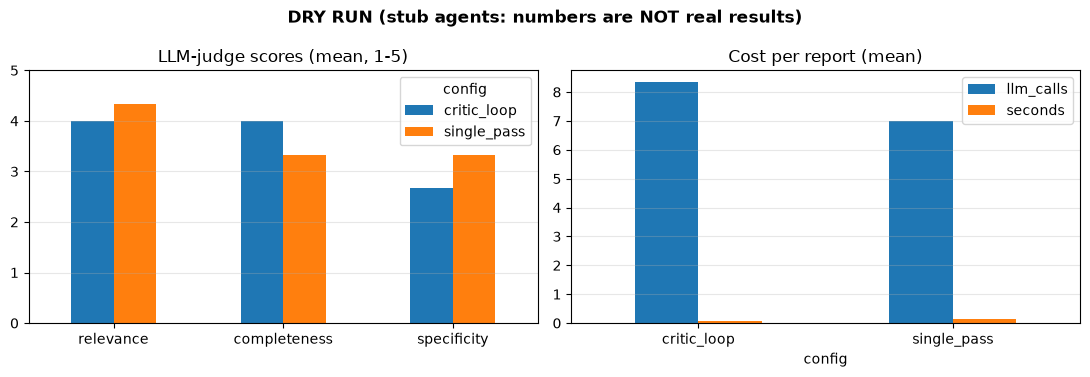

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
judge_cols = ["relevance", "completeness", "specificity"]
results.groupby("config")[judge_cols].mean().T.plot.bar(ax=axes[0], rot=0, ylim=(0, 5),
                                                         title="LLM-judge scores (mean, 1-5)")
cost = results.groupby("config")[["llm_calls", "seconds"]].mean()
cost.plot.bar(ax=axes[1], rot=0, title="Cost per report (mean)")
for ax in axes:
    ax.grid(axis="y", alpha=0.3)
title = "DRY RUN (stub agents: numbers are NOT real results)" if DRY_RUN else "Evaluation results"
fig.suptitle(title, fontweight="bold")
plt.tight_layout()
plt.show()

## 9 · Observations & Decisions

> **Status (2026-11-19):** the pipeline was verified end-to-end in `DRY_RUN` mode (stub agents, fake chat models):
> runs, metrics, callback counting, judging, resumable CSV logging and charts all work. **The numbers above are
> placeholders, not findings.** Real results require ~(N_QUESTIONS × 2 configs × ~30) LLM requests, which exceeds the
> free OpenRouter quota (50/day). Set `DRY_RUN = False` after adding OpenRouter credits or a Groq key, then fill in
> this section from the real table.

**What to look for in the real run**
- Does `critic_loop` raise *completeness* and *specificity* enough to justify its extra LLM calls and time?
- Is `grounding_rate` high (most claims cite really-retrieved URLs) and `citation_problems` ≈ 0?
- Which question *kinds* score lowest (likely comparative/trend questions that need more sources)?

**Decisions already made**
1. Evaluation = deterministic metrics (free, objective) + LLM-as-judge with a different model (cheap, subjective).
2. Results are logged per run to CSV for resumable, multi-day evaluation; Phase 3 will mirror this as a LangSmith
   dataset + experiment so runs can be compared in the LangSmith UI.
3. The `DRY_RUN` stub path doubles as a fast integration test of the evaluation code.